In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
features = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

data = pd.read_csv(
    "./assn2 material/housing.data",
    sep=r"\s+",
    header=None,
    names=features
)

X = data.drop(columns="MEDV").to_numpy()
y = data["MEDV"].to_numpy()

In [3]:
def polynomial_features(X, degree):
    """Create polynomial features without cross-terms."""
    features = [np.ones(X.shape[0])]

    for power in range(1, degree + 1):
        features.append(X ** power)

    return np.column_stack(features)

def polynomial_regression(X_train, y_train, X_test, y_test, degree):
    Phi_train = polynomial_features(X_train, degree)
    Phi_test = polynomial_features(X_test, degree)

    weights = np.linalg.lstsq(Phi_train, y_train, rcond=None)[0]

    train_pred = Phi_train @ weights
    test_pred = Phi_test @ weights

    train_rms = np.sqrt(np.mean((y_train - train_pred) ** 2))
    test_rms = np.sqrt(np.mean((y_test - test_pred) ** 2))

    return train_rms, test_rms, weights

X_train_raw, X_test_raw = X[:100], X[100:]
y_train, y_test = y[:100], y[100:]

# normalize training data
mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

degrees = range(1, 8)
train_errors = []
test_errors = []

for degree in degrees:
    train_rms, test_rms, weights = polynomial_regression(
        X_train, y_train, X_test, y_test, degree
    )

    train_errors.append(train_rms)
    test_errors.append(test_rms)

    print(
        f"Degree {degree}: "
        f"Training RMS = {train_rms:.4f}, "
        f"Testing RMS = {test_rms:.4f}"
    )


Degree 1: Training RMS = 2.0372, Testing RMS = 36.4449
Degree 2: Training RMS = 1.5781, Testing RMS = 1097.1883
Degree 3: Training RMS = 1.4491, Testing RMS = 48672.8178
Degree 4: Training RMS = 1.2705, Testing RMS = 21859310.1962
Degree 5: Training RMS = 1.0966, Testing RMS = 18358040619.9225
Degree 6: Training RMS = 1.0725, Testing RMS = 5024088561899.5869
Degree 7: Training RMS = 0.8815, Testing RMS = 6879332105890630.0000


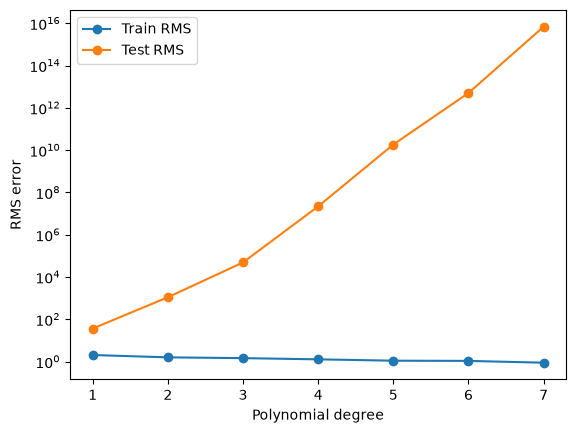

In [4]:
# plot for part a
plt.plot(degrees, train_errors, marker='o', label='Train RMS')
plt.plot(degrees, test_errors, marker='o', label='Test RMS')
plt.xlabel('Polynomial degree')
plt.ylabel('RMS error')
plt.yscale('log')
plt.legend()
plt.show()

We can see that the training error decreases as the degree of the polynomial increases, which is expected since higher-degree polynomials can fit the training data better. This also leads to overfitting, as shown by the increasing testing error for higher-degree polynomials. The best test performance is at degree 1.

In [5]:
Phi_train = polynomial_features(X_train, degree=1)
weights = np.linalg.lstsq(Phi_train, y_train, rcond=None)[0]

print("Bias:", weights[0])
print("RM weight:", weights[6])
print("DIS weight:", weights[8])
print("All weights:", weights)

Bias: 22.309000000000005
RM weight: 4.195634385830218
DIS weight: 0.010715449340658822
All weights: [ 2.23090000e+01 -1.33797373e+00  1.22993392e-01 -5.31064627e-01
  4.44089210e-16  1.00265142e+00  4.19563439e+00 -2.16627489e+00
  1.07154493e-02 -1.93778224e-01 -3.48630963e-01  2.61264017e-01
  1.81073037e-01  1.48761127e-01]


The RM weight (4.196) seems reasonable because houses with more rooms generally have higher values. The DIS weight (0.0107) is very small, suggesting that distance has little effect on the prediction when other features are held constant.

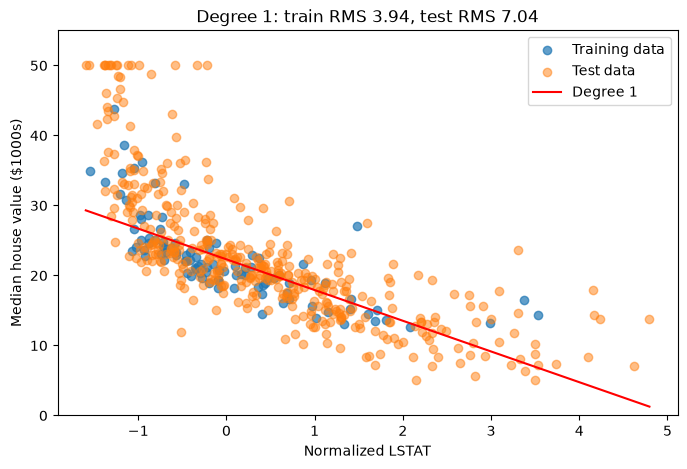

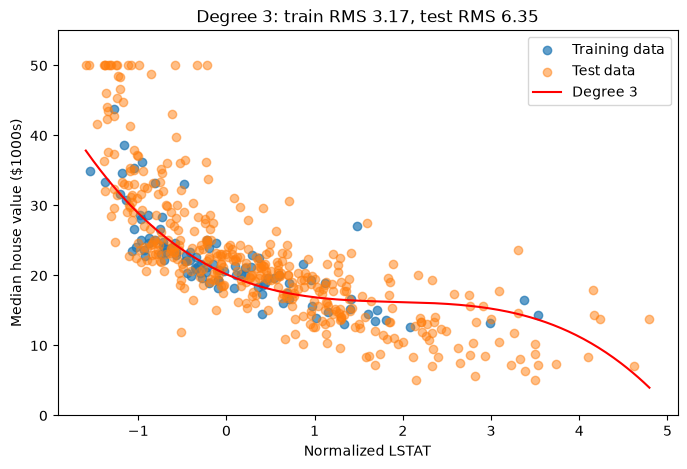

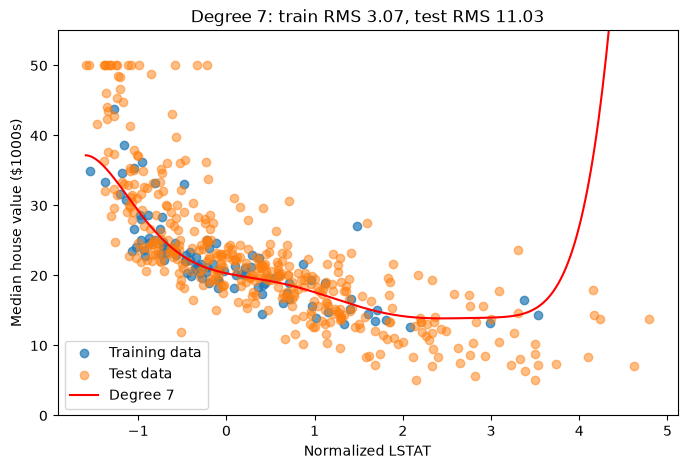

In [6]:
def polynomial_regression_1d_vis(x_train, y_train, x_test, y_test, degree, feature_name):
    # x_train, x_test: single normalized columns from the part a arrays
    train_rms, test_rms, w = polynomial_regression(x_train, y_train, x_test, y_test, degree)

    grid = np.linspace(min(x_train.min(), x_test.min()), max(x_train.max(), x_test.max()), 300)
    curve = polynomial_features(grid, degree) @ w

    plt.figure(figsize=(8, 5))
    plt.scatter(x_train, y_train, label="Training data", alpha=0.7)
    plt.scatter(x_test, y_test, label="Test data", alpha=0.5)
    plt.plot(grid, curve, "r-", label=f"Degree {degree}")
    plt.ylim(min(y_train.min(), y_test.min()) - 5, max(y_train.max(), y_test.max()) + 5)
    plt.xlabel(f"Normalized {feature_name}")
    plt.ylabel("Median house value ($1000s)")
    plt.title(f"Degree {degree}: train RMS {train_rms:.2f}, test RMS {test_rms:.2f}")
    plt.legend()
    plt.show()
    
feature_idx = 12

for d in [1, 3, 7]:
    polynomial_regression_1d_vis(X_train[:, 12], y_train, X_test[:, 12], y_test, d, "LSTAT")

Degree 1: The line captures the downward trend but misses the curvature, so it underfits (train RMS = 3.94, test RMS = 7.04).

Degree 3: It gives the best fit (train = 3.17, test = 6.35).

Degree 7: The curve oscillates to chase training points, so it overfits. Train RMS is only slightly lower (3.07), but test RMS is much higher (11.03).

lambda = 0: avg validation RMS = 178.3534
lambda = 0.01: avg validation RMS = 10.1317
lambda = 0.1: avg validation RMS = 8.6588
lambda = 1: avg validation RMS = 8.3940
lambda = 10: avg validation RMS = 8.5226
lambda = 100: avg validation RMS = 7.3556
lambda = 1000: avg validation RMS = 5.9277
Best lambda: 1000


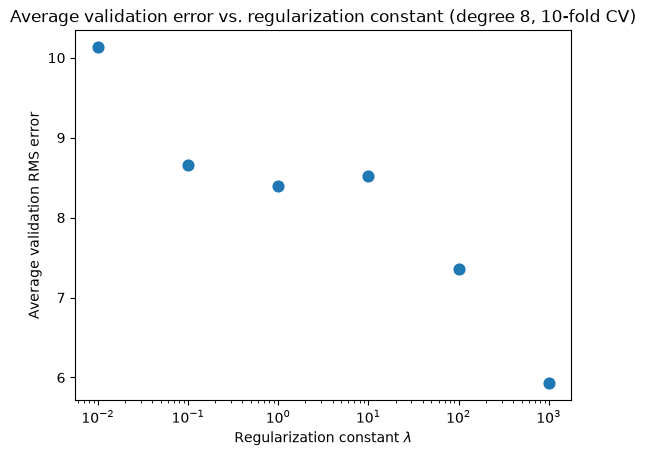

In [7]:
def polynomial_regression_reg(x_train, y_train, degree, lam):
    Phi = polynomial_features(x_train, degree)
    P = np.sqrt(lam) * np.eye(degree + 1)
    P[0, 0] = 0
    Phi_aug = np.vstack([Phi, P])
    y_aug = np.concatenate([y_train, np.zeros(degree + 1)])
    return np.linalg.lstsq(Phi_aug, y_aug, rcond=None)[0]

def cross_validate(x, y, degree, lambdas, k=10, seed=0):
    idx = np.random.default_rng(seed).permutation(len(x))
    folds = np.array_split(idx, k)
    avg_errors = []
    for lam in lambdas:
        fold_errors = []
        for i in range(k):
            val = folds[i]
            tr = np.concatenate([folds[j] for j in range(k) if j != i])
            w = polynomial_regression_reg(x[tr], y[tr], degree, lam)
            pred = polynomial_features(x[val], degree) @ w
            fold_errors.append(np.sqrt(np.mean((y[val] - pred) ** 2)))
        avg_errors.append(np.mean(fold_errors))
    return np.array(avg_errors)

# first 100 points, normalized with their own statistics
X_train_raw = X[:100]
y_train = y[:100]

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std

# only the 2nd feature (index 1)
feature_idx = 1
x = X_train[:, feature_idx]

lambdas = [0, 0.01, 0.1, 1, 10, 100, 1000]
avg_val_errors = cross_validate(x, y_train, degree=8, lambdas=lambdas)

for lam, e in zip(lambdas, avg_val_errors):
    print(f"lambda = {lam}: avg validation RMS = {e:.4f}")

best_lam = lambdas[int(np.argmin(avg_val_errors))]
print("Best lambda:", best_lam)

plt.scatter(lambdas[1:], avg_val_errors[1:], s=60, label='Regularized')
plt.xscale('log')
plt.xlabel('Regularization constant $\\lambda$')
plt.ylabel('Average validation RMS error')
plt.title('Average validation error vs. regularization constant (degree 8, 10-fold CV)')
plt.show()

Without regularization the degree 8 polynomial overfits badly, with an average validation RMS of 178.35. Adding the penalty reduces the error sharply, reaching its lowest value of 5.93 at $\lambda$ = 1000. I would choose $\lambda$ = 1000.

Gaussian regression all results:
K = 5: train RMS = 3.5712, test RMS = 10.6803
K = 15: train RMS = 2.1720, test RMS = 8.7528
K = 25: train RMS = 1.5906, test RMS = 9.4498
K = 35: train RMS = 1.4642, test RMS = 9.6442
K = 45: train RMS = 1.2121, test RMS = 8.4540
K = 55: train RMS = 1.1100, test RMS = 10.4087
K = 65: train RMS = 1.0330, test RMS = 9.1681
K = 75: train RMS = 0.9481, test RMS = 8.8415
K = 85: train RMS = 0.8646, test RMS = 10.5398
K = 95: train RMS = 0.2858, test RMS = 54.4899


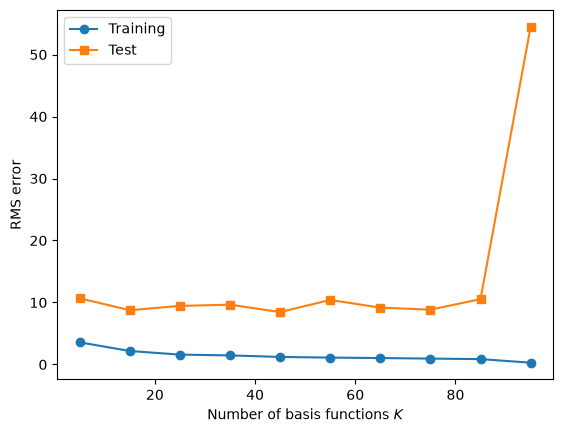

In [8]:
def gaussian_features(X, centers, s):
    d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    phi = np.exp(-d2 / (2 * s ** 2))
    return np.column_stack([np.ones(X.shape[0]), phi])

def gaussian_regression(X_train, y_train, X_test, y_test, Ks, s, seed=0):
    perm = np.random.default_rng(seed).permutation(len(X_train))
    train_errors, test_errors = [], []

    for K in Ks:
        centers = X_train[perm[:K]]
        Phi_train = gaussian_features(X_train, centers, s)
        Phi_test = gaussian_features(X_test, centers, s)

        w = np.linalg.lstsq(Phi_train, y_train, rcond=None)[0]

        train_errors.append(np.sqrt(np.mean((Phi_train @ w - y_train) ** 2)))
        test_errors.append(np.sqrt(np.mean((Phi_test @ w - y_test) ** 2)))

    return train_errors, test_errors

# width: median pairwise distance between training points
diffs = X_train[:, None, :] - X_train[None, :, :]
dists = np.sqrt((diffs ** 2).sum(axis=2))
s = np.median(dists[np.triu_indices_from(dists, k=1)])

Ks = list(range(5, 100, 10))

g_train, g_test = gaussian_regression(X_train, y_train, X_test, y_test, Ks, s)

print("Gaussian regression all results:")
for K, tr, te in zip(Ks, g_train, g_test):
	print(f"K = {K}: train RMS = {tr:.4f}, test RMS = {te:.4f}")

plt.plot(Ks, g_train, 'o-', label='Training')
plt.plot(Ks, g_test, 's-', label='Test')
plt.xlabel('Number of basis functions $K$')
plt.ylabel('RMS error')
plt.legend()
plt.show()

As the number of basis functions increases, the training error generally decreases, while the test RMS error fluatuates without a clear trend. At K = 95, the test error increases sharply while the training error continues to decrease, indicating overfitting. The best test performance is at K = 45.

lambda = 0: avg validation RMS = 7.8843
lambda = 0.01: avg validation RMS = 2.0302
lambda = 0.1: avg validation RMS = 2.2225
lambda = 1: avg validation RMS = 2.6127
lambda = 10: avg validation RMS = 3.2002
lambda = 100: avg validation RMS = 4.2928
lambda = 1000: avg validation RMS = 5.3457
Best lambda: 0.01


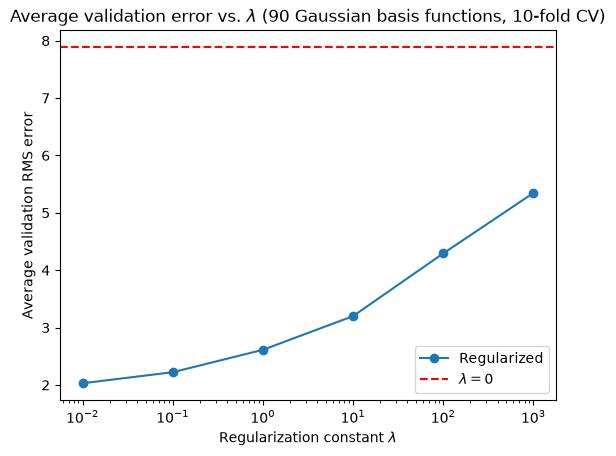

In [9]:
def gaussian_features(X, centers, sigma):
    # X: (n, d), centers: (m, d) -> (n, m+1), first column is the bias
    d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    return np.hstack([np.ones((len(X), 1)), np.exp(-d2 / (2 * sigma ** 2))])

def gaussian_regression_reg(X_train, y_train, centers, sigma, lam):
    Phi = gaussian_features(X_train, centers, sigma)
    p = Phi.shape[1]
    P = np.sqrt(lam) * np.eye(p)
    P[0, 0] = 0                      # don't regularize the bias
    Phi_aug = np.vstack([Phi, P])
    y_aug = np.concatenate([y_train, np.zeros(p)])
    return np.linalg.lstsq(Phi_aug, y_aug, rcond=None)[0]

def cross_validate_gaussian(X, y, sigma, lambdas, k=10, seed=0):
    idx = np.random.default_rng(seed).permutation(len(X))
    folds = np.array_split(idx, k)
    avg_errors = []
    for lam in lambdas:
        fold_errors = []
        for i in range(k):
            val = folds[i]
            tr = np.concatenate([folds[j] for j in range(k) if j != i])
            centers = X[tr]          # 90 training points -> 90 basis functions, no leakage
            w = gaussian_regression_reg(X[tr], y[tr], centers, sigma, lam)
            pred = gaussian_features(X[val], centers, sigma) @ w
            fold_errors.append(np.sqrt(np.mean((y[val] - pred) ** 2)))
        avg_errors.append(np.mean(fold_errors))
    return np.array(avg_errors)

# first 100 points, ALL features, normalized with their own statistics
X_train_raw = X[:100]
y_train = y[:100]
mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1
X_train = (X_train_raw - mean) / std

# bandwidth: median pairwise distance heuristic
dists = np.sqrt(((X_train[:, None, :] - X_train[None, :, :]) ** 2).sum(axis=2))
sigma = np.median(dists[np.triu_indices(len(X_train), k=1)])

lambdas = [0, 0.01, 0.1, 1, 10, 100, 1000]
avg_val_errors = cross_validate_gaussian(X_train, y_train, sigma, lambdas)

for lam, e in zip(lambdas, avg_val_errors):
    print(f"lambda = {lam}: avg validation RMS = {e:.4f}")

best_lam = lambdas[int(np.argmin(avg_val_errors))]
print("Best lambda:", best_lam)

plt.semilogx(lambdas[1:], avg_val_errors[1:], 'o-', label='Regularized')
plt.axhline(avg_val_errors[0], color='r', linestyle='--', label=r'$\lambda=0$')
plt.xlabel('Regularization constant $\\lambda$')
plt.ylabel('Average validation RMS error')
plt.title('Average validation error vs. $\\lambda$ (90 Gaussian basis functions, 10-fold CV)')
plt.legend()
plt.show()

I would choose $\lambda$ = 0.01 because it has the lowest validation error (2.03). 